# Notebook 02 – Data Preparation and Feature Engineering

Join the S-N data to its metadata, filter it, build the target and input features, and save the modelling dataset.

- No measured value is changed; rows are removed only by a named filter step.
- Every input is known before the fatigue test. Life, the run-out flag and all identifiers are never features.
- Nothing here is fitted to the data (only fixed rules), so preparing the data before the train/test split cannot leak information.

**Input:** `data/raw/FatigueData-AM2022.xlsx` and `results/audit/confirmed_columns.json` (notebook 01).
**Output:** `data/processed/modelling_dataset.csv`, `sn_cohort_with_runouts.csv`, `feature_config.json` and audit tables in `results/audit/`.

## 1. Setup

Import the libraries and helper functions, and read the confirmed column names from notebook 01.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import data_utils as du
import feature_utils as fu
from evaluation_utils import set_plot_style, save_figure, PALETTE

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

AUDIT_DIR = PROJECT_ROOT / "results" / "audit"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

confirmed = json.loads((AUDIT_DIR / "confirmed_columns.json").read_text(encoding="utf8"))
print("Run-out coding confirmed in notebook 01:", confirmed["columns"]["runout_flag"]["coding_confirmed_from_data"])
print("Counts confirmed in notebook 01        :", confirmed["counts_from_file"])

Run-out coding confirmed in notebook 01: True
Counts confirmed in notebook 01        : {'sn_points': 15146, 'sn_curves': 1610, 'sn_articles': 459, 'runout_points': 1851}


## 2. Load and join

Load the S-N and parameter sheets and join them on `dataset_id`. `row_id` keeps the position of each point in the original S-N sheet.

In [2]:
workbook_path = du.ensure_raw_data("FatigueData-AM2022.xlsx")
sn, _ = du.load_sheet(du.SHEET_SN, workbook_path)
param, _ = du.load_sheet(du.SHEET_PARAM, workbook_path)

sn = sn.reset_index(drop=True)
sn.insert(0, "row_id", np.arange(len(sn)))
param["article_id"] = du.build_article_id(param)

joined = du.join_sn_to_parameter(sn, param)

assert len(joined) == len(sn) == confirmed["counts_from_file"]["sn_points"]
print(f"S-N rows before the join : {len(sn):,}")
print(f"Rows after the join      : {len(joined):,}")
print(f"Rows with metadata       : {int(joined['_matched'].sum()):,}")
print(f"S-N rows without metadata: {int((~joined['_matched']).sum()):,}")
print(f"Parameter rows not used  : {int((~param['dataset_id'].isin(sn['dataset_id'])).sum()):,} (the e-N and da/dN datasets)")

S-N rows before the join : 15,146
Rows after the join      : 15,146
Rows with metadata       : 15,146
S-N rows without metadata: 0
Parameter rows not used  : 850 (the e-N and da/dN datasets)


## 3. Parsing the load ratio R

Convert the R text to numbers. Cells holding two values (a lower and an upper bound) are set to missing, not averaged.

In [3]:
joined["R_text"] = joined["R"]
joined["R"], r_kind = du.single_value_or_nan(joined["R_text"])

r_parse = (joined.assign(kind=r_kind).groupby("kind")
           .agg(points=("row_id", "size"), curves=("dataset_id", "nunique"), articles=("article_id", "nunique")))
r_parse.to_csv(AUDIT_DIR / "R_parsing_summary.csv")
display(r_parse)
print("Two-value cells found:", sorted(joined.loc[r_kind == "range", "R_text"].astype(str).unique()))
print("Largest single R value:", joined["R"].max(), "| smallest:", joined["R"].min())

,points,curves,articles
kind,,,
missing,170,20,6
range,39,3,2
single,14937,1587,452


Two-value cells found: ['0, 0.1', '0.04, 0.06']
Largest single R value: 0.7 | smallest: -10.0


*Note:* curves without a single R value are removed at filter step 5.

## 4. The filter funnel

Apply the filters in a fixed order and count the points, curves and articles left after each step.

| Step | Filter | Reason |
|---|---|---|
| 1 | All S-N rows | Starting point |
| 2 | Matched to parameter metadata | A point without metadata has no features |
| 3 | σa > 0, N > 0, both finite | log10 must exist |
| 4 | Failures only (run-out flag = 0) | A run-out is only a lower bound on life |
| 5 | Single R value and R < 1 | R is a core input |
| 6 | Recorded test temperature 15–35 °C | Temperature changes life strongly and is not a feature |
| 7 | Exact cross-article duplicates removed | A copied point would leak under article-held-out validation |

In [4]:
funnel = []
steps = {}

current = joined
funnel.append(du.funnel_row(1, "All S-N rows", current))
steps[1] = current

previous, current = current, current[current["_matched"]]
funnel.append(du.funnel_row(2, "Matched to parameter metadata", current, previous))
steps[2] = current

valid = (current["stress_amplitude"] > 0) & (current["N"] > 0) & np.isfinite(current["stress_amplitude"]) & np.isfinite(current["N"])
previous, current = current, current[valid]
funnel.append(du.funnel_row(3, "Valid measurement (sigma_a > 0, N > 0, finite)", current, previous))
steps[3] = current

previous, current = current, current[current["runout"] == 0]
funnel.append(du.funnel_row(4, "Failures only (run-out flag = 0)", current, previous))
steps[4] = current

previous, current = current, current[current["R"].notna() & (current["R"] < 1)]
funnel.append(du.funnel_row(5, "R present (single value) and R < 1", current, previous))
steps[5] = current

previous, current = current, current[current["test_temperature_c"].between(15, 35)]
funnel.append(du.funnel_row(6, "Nominal room temperature (recorded 15 to 35 degC)", current, previous))
steps[6] = current

pd.DataFrame(funnel)

,step,filter,points,curves,articles,points_removed,curves_removed,articles_removed
0,1,All S-N rows,15146,1610,459,0,0,0
1,2,Matched to parameter metadata,15146,1610,459,0,0,0
2,3,"Valid measurement (sigma_a > 0, N > 0, finite)",15146,1610,459,0,0,0
3,4,Failures only (run-out flag = 0),13295,1609,459,1851,1,0
4,5,R present (single value) and R < 1,13116,1586,452,179,23,7
5,6,Nominal room temperature (recorded 15 to 35 degC),12666,1533,440,450,53,12


### 4.1 Step 7: exact duplicates

Find rows with identical stress, life, alloy and R. Only copies in a different article are removed; every duplicate is logged in `results/audit/duplicate_log.csv`.

In [5]:
dup_key = ["material_str", "stress_amplitude", "N", "R"]
work = current.assign(material_str=current["material"].astype(str))
is_dup = work.duplicated(subset=dup_key, keep=False)
dup_rows = work[is_dup].copy()

group_stats = dup_rows.groupby(dup_key).agg(n_curves=("dataset_id", "nunique"), n_articles=("article_id", "nunique"))
dup_rows = dup_rows.join(group_stats, on=dup_key)
dup_rows["duplicate_kind"] = np.select(
    [dup_rows["n_articles"] > 1, dup_rows["n_curves"] > 1],
    ["across articles", "across curves, same article"],
    default="within one curve",
)
# Within a duplicate group that spans articles, keep the first row (lowest row_id) and remove the later copies in other articles.
dup_rows = dup_rows.sort_values(["stress_amplitude", "N", "row_id"])
first_article = dup_rows.groupby(dup_key)["article_id"].transform("first")
dup_rows["action"] = np.where((dup_rows["duplicate_kind"] == "across articles") & (dup_rows["article_id"] != first_article), "removed", "kept")

duplicate_log = dup_rows[["row_id", "dataset_id", "article_id", "material_str", "stress_amplitude", "N", "R", "duplicate_kind", "action"]].rename(
    columns={"dataset_id": "curve_id", "material_str": "alloy"})
duplicate_log.to_csv(AUDIT_DIR / "duplicate_log.csv", index=False, encoding="utf-8-sig")

rows_to_remove = set(duplicate_log.loc[duplicate_log["action"] == "removed", "row_id"])
previous, current = current, current[~current["row_id"].isin(rows_to_remove)]
funnel.append(du.funnel_row(7, "Exact cross-article duplicates removed", current, previous))
steps[7] = current

print("Exact duplicate rows in the cohort, by kind and action:")
print(duplicate_log.groupby(["duplicate_kind", "action"]).size().rename("rows").to_string() if len(duplicate_log) else "none")

funnel_table = pd.DataFrame(funnel)
funnel_table.to_csv(AUDIT_DIR / "filter_funnel.csv", index=False)
funnel_table

Exact duplicate rows in the cohort, by kind and action:
duplicate_kind    action
within one curve  kept      2


,step,filter,points,curves,articles,points_removed,curves_removed,articles_removed
0,1,All S-N rows,15146,1610,459,0,0,0
1,2,Matched to parameter metadata,15146,1610,459,0,0,0
2,3,"Valid measurement (sigma_a > 0, N > 0, finite)",15146,1610,459,0,0,0
3,4,Failures only (run-out flag = 0),13295,1609,459,1851,1,0
4,5,R present (single value) and R < 1,13116,1586,452,179,23,7
5,6,Nominal room temperature (recorded 15 to 35 degC),12666,1533,440,450,53,12
6,7,Exact cross-article duplicates removed,12666,1533,440,0,0,0


Plot the filter funnel and keep the final cohort.

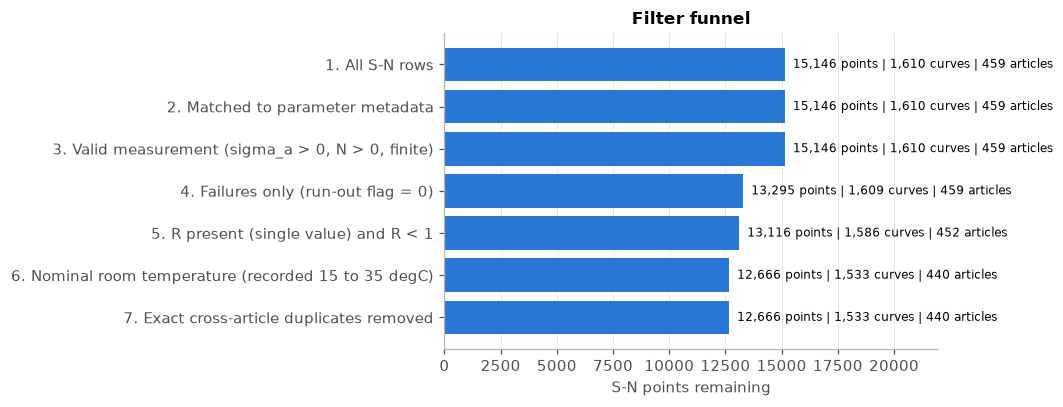

Final cohort: 12,666 points, 1,533 curves, 440 articles
Run-outs excluded at step 4: 1,851 points (12.2% of all S-N points)


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [f"{row.step}. {row.filter}" for row in funnel_table.itertuples()][::-1]
ax.barh(labels, funnel_table["points"][::-1], color=PALETTE[0])
for y, row in enumerate(funnel_table[::-1].itertuples()):
    ax.text(row.points, y, f"  {row.points:,} points | {row.curves:,} curves | {row.articles} articles", va="center", fontsize=8)
ax.set(xlabel="S-N points remaining", title="Filter funnel", xlim=(0, funnel_table["points"].max() * 1.45))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, FIG_DIR / "02_filter_funnel.png")
plt.show()

cohort = current.copy()
runouts_removed = int(funnel_table.loc[funnel_table["step"] == 4, "points_removed"].iloc[0])
print(f"Final cohort: {len(cohort):,} points, {cohort['dataset_id'].nunique():,} curves, {cohort['article_id'].nunique()} articles")
print(f"Run-outs excluded at step 4: {runouts_removed:,} points ({100 * runouts_removed / len(joined):.1f}% of all S-N points)")

### 4.2 Test temperature check

Check whether a recorded 25 °C is a real value or the database default for an unreported temperature, and label each row by its temperature evidence (explicit, probably reported or ambiguous).

In [7]:
evidence = du.temperature_evidence(joined)
evidence_by_row = pd.Series(evidence.to_numpy(), index=joined["row_id"].to_numpy())
cohort["temperature_evidence"] = cohort["row_id"].map(evidence_by_row)

# 1. How missing values are stored in the parameter sheet (all 2,460 datasets, all data types)
def is_empty(values):
    return values.isna() | values.astype(str).str.strip().isin(["", "nan", "None"])

check_columns = {"test_temperature_c": "test temperature", "test_environment": "test environment", "kt": "Kt",
                 "frequency_hz": "test frequency", "test_standard": "test standard", "uts_mpa": "UTS", "modulus_gpa": "elastic modulus"}
storage = pd.DataFrame({
    "column": list(check_columns.values()),
    "empty cells": [int(is_empty(param[c]).sum()) for c in check_columns],
    "most common value": [param[c].astype(str).value_counts().index[0] for c in check_columns],
    "share of non-empty cells with that value": [float(param[c].astype(str).value_counts(normalize=True).iloc[0]) for c in check_columns],
})
display(storage)

# The JSON version of the database (downloaded with the workbook, read here only for this check)
import json
with open(du.ensure_raw_data("FatigueData-AM2022.json"), encoding="utf-8") as handle:     # downloaded and MD5-checked if absent
    json_articles = json.load(handle)["fatiguedata_am2022"]["articles"]
json_temps = [tuple(ds["testing"]["fat_temp"]) for art in json_articles for ds in art["scidata"]["datasets"]]
json_counts = pd.Series([t[0] if len(t) == 1 else ("empty" if not t else "several") for t in json_temps]).value_counts()
print(f"JSON file: {len(json_temps):,} datasets; empty temperature entries: {int(json_counts.get('empty', 0))}; recorded as 25 °C: {int(json_counts.get(25.0, 0)):,}")

# 2. Recorded temperature of the 1,610 S-N curves
sn_curves = joined.drop_duplicates("dataset_id")
band = pd.Series(np.select([sn_curves["test_temperature_c"] == 25, sn_curves["test_temperature_c"].between(15, 35)],
                           ["25 °C (equal to the default)", "15–35 °C, another value"], default="above 35 °C"), name="recorded temperature")
print("S-N curves by recorded temperature:")
print(band.value_counts().to_string())
print("Values recorded between 15 and 35 °C:", sorted(sn_curves.loc[sn_curves["test_temperature_c"].between(15, 35), "test_temperature_c"].unique().tolist()))

# 3. The cohort by temperature evidence
temperature_audit = (cohort.groupby("temperature_evidence")
                     .agg(points=("row_id", "size"), curves=("dataset_id", "nunique"), articles=("article_id", "nunique"),
                          recorded_values=("test_temperature_c", lambda s: ", ".join(str(int(v)) for v in sorted(s.unique())))))
temperature_audit["share of points"] = temperature_audit["points"] / len(cohort)
temperature_audit.to_csv(AUDIT_DIR / "test_temperature_audit.csv")
display(temperature_audit)

explicit_only = cohort[cohort["test_temperature_c"] != 25]
print(f"If every row recorded at 25 °C were excluded: {len(explicit_only)} points, {explicit_only['dataset_id'].nunique()} curves, "
      f"{explicit_only['article_id'].nunique()} articles would remain.")

,column,empty cells,most common value,share of non-empty cells with that value
0,test temperature,0,25,0.944309
1,test environment,0,air,0.979675
2,Kt,0,1.0,0.961382
3,test frequency,477,20,0.165910
4,test standard,1560,ASTM E647,0.365556
5,UTS,1228,1176.0,0.013799
6,elastic modulus,1958,187.3,0.051793


JSON file: 2,460 datasets; empty temperature entries: 0; recorded as 25 °C: 2,323
S-N curves by recorded temperature:
recorded temperature
25 °C (equal to the default)    1545
above 35 °C                       53
15–35 °C, another value           12
Values recorded between 15 and 35 °C: [20, 23, 25]


,points,curves,articles,recorded_values,share of points
temperature_evidence,,,,,
"25, article reports other temps",131,19,11,25,0.010343
"25, default or reported",12406,1502,425,25,0.979473
"explicit, not the default",129,12,4,"20, 23",0.010185


If every row recorded at 25 °C were excluded: 129 points, 12 curves, 4 articles would remain.


*Note:* 25 °C is the default for unreported temperatures, so 98% of the cohort is ambiguous and the cohort is a *nominal* room-temperature cohort. The `temperature_evidence` label is saved for sensitivity check S6 in notebook 04.

### 4.3 Run-outs

Run-outs are excluded from the primary cohort because their true life is unknown (right-censored). The same cohort with its run-outs is saved for the sensitivity analysis, and the two run-out counts (whole sheet and cohort) are reconciled.

In [8]:
# The same cohort but keeping run-outs: all filters except step 4. Used only by the run-out sensitivity analysis.
with_runouts = steps[3]
with_runouts = with_runouts[with_runouts["R"].notna() & (with_runouts["R"] < 1)]
with_runouts = with_runouts[with_runouts["test_temperature_c"].between(15, 35)]
with_runouts = with_runouts[~with_runouts["row_id"].isin(rows_to_remove)].copy()
with_runouts["temperature_evidence"] = with_runouts["row_id"].map(evidence_by_row)

comparison = pd.DataFrame({
    "failures only (primary)": du.count_points_curves_articles(cohort),
    "failures + run-outs (sensitivity)": du.count_points_curves_articles(with_runouts),
}).T
comparison["run-out points"] = [0, int((with_runouts["runout"] == 1).sum())]
display(comparison)

lost_curves = sorted(set(with_runouts["dataset_id"]) - set(cohort["dataset_id"]))
print("Curves that consist of run-outs only (lost in the primary cohort):", lost_curves)

# Two run-out counts are quoted in this project: 1,851 (the whole S-N sheet) and 1,748 (the cohort).
# The funnel removes every run-out at step 4, because that step comes first. Attributing each run-out to the
# later step that would also have removed it reconciles the two numbers.
valid = steps[3]
is_runout = valid["runout"] == 1
r_usable = valid["R"].notna() & (valid["R"] < 1)
nominal_rt = valid["test_temperature_c"].between(15, 35)
not_duplicate = ~valid["row_id"].isin(rows_to_remove)
populations = [
    ("All valid S-N points (whole sheet, funnel step 3)", pd.Series(True, index=valid.index)),
    ("  of which on curves without a single R below 1 (step 5)", ~r_usable),
    ("  of which recorded outside 15 to 35 degC (step 6)", r_usable & ~nominal_rt),
    ("  of which exact cross-article duplicates (step 7)", r_usable & nominal_rt & ~not_duplicate),
    ("Nominal room-temperature cohort (sn_cohort_with_runouts.csv)", r_usable & nominal_rt & not_duplicate),
]
runout_reconciliation = pd.DataFrame([{"population": label, "run-outs": int((is_runout & mask).sum()), "failures": int((~is_runout & mask).sum()),
                                       "run-out share": float(is_runout[mask].mean()) if mask.any() else np.nan} for label, mask in populations])
assert runout_reconciliation["run-outs"].iloc[0] == runout_reconciliation["run-outs"].iloc[1:].sum()
assert runout_reconciliation["run-outs"].iloc[-1] == int((with_runouts["runout"] == 1).sum())
assert runout_reconciliation["failures"].iloc[-1] == len(cohort)
runout_reconciliation.to_csv(AUDIT_DIR / "runout_reconciliation.csv", index=False)
runout_reconciliation

,points,curves,articles,run-out points
failures only (primary),12666,1533,440,0
failures + run-outs (sensitivity),14414,1534,440,1748


Curves that consist of run-outs only (lost in the primary cohort): [41]


,population,run-outs,failures,run-out share
0,"All valid S-N points (whole sheet, funnel step 3)",1851,13295,0.122210
1,of which on curves without a single R below 1 (step 5),30,179,0.143541
2,of which recorded outside 15 to 35 degC (step 6),73,450,0.139579
3,of which exact cross-article duplicates (step 7),0,0,NaN
4,Nominal room-temperature cohort (sn_cohort_with_runouts.csv),1748,12666,0.121271


*Note:* the funnel gives **12,666 failure points, 1,533 curves and 440 articles**. 1,851 run-outs are removed from the whole sheet; 1,748 of them belong to the nominal room-temperature cohort.

## 5. Target and stress features

Create the target `log_N` = log10(N) and the stress features `log_sa` = log10(σa) and `log_swt`, the stress-based Smith–Watson–Topper amplitude σa·√(2/(1 − R)) from nominal stresses. `sigma_max` and `sigma_mean` are for plots and checks only. A hand calculation checks the formulas.

In [9]:
def add_target_and_stress_features(frame):
    out = frame.copy()
    out["log_N"] = np.log10(out["N"])
    return fu.add_stress_features(out)

cohort = add_target_and_stress_features(cohort)
with_runouts = add_target_and_stress_features(with_runouts)

# Worked check against the hand calculation in the domain notes: sigma_max = 500 MPa, R = 0.1 -> sigma_a = 225, SWT = 335 MPa.
check = fu.add_stress_features(pd.DataFrame({"stress_amplitude": [225.0], "R": [0.1]}))
print(f"Check: sigma_a = 225 MPa, R = 0.1 -> sigma_max = {check['sigma_max'][0]:.0f} MPa, sigma_mean = {check['sigma_mean'][0]:.0f} MPa, SWT = {10 ** check['log_swt'][0]:.0f} MPa")

cohort[["stress_amplitude", "R", "N", "log_N", "log_sa", "log_swt", "sigma_max", "sigma_mean"]].describe().round(3)

Check: sigma_a = 225 MPa, R = 0.1 -> sigma_max = 500 MPa, sigma_mean = 275 MPa, SWT = 335 MPa


,stress_amplitude,R,N,log_N,log_sa,log_swt,sigma_max,sigma_mean
count,12666.000,12666.000,1.266600e+04,12666.000,12666.000,12666.000,12666.000,12666.000
mean,295.391,-0.470,1.171466e+07,5.321,2.373,2.457,438.470,143.079
std,193.093,0.591,1.178183e+08,0.993,0.306,0.296,308.096,206.913
min,9.884,-10.000,9.711000e+00,0.987,0.995,0.995,9.884,-224.531
25%,142.100,-1.000,5.380297e+04,4.731,2.153,2.247,214.760,0.000
50%,262.294,-1.000,1.760876e+05,5.246,2.419,2.509,384.826,0.000
75%,388.171,0.100,6.950835e+05,5.842,2.589,2.673,599.492,252.246
max,1591.682,0.700,8.496147e+09,9.929,3.202,3.344,4416.178,3312.133


*Note:* the standard deviation of the target (about 0.99) is the error of a model that always predicts the average life, and is the reference for every RMSE in notebooks 03 and 04.

## 6. Categorical features

Add the alloy, heat-treatment class, surface class and test-type class using fixed text rules.

- **Heat-treatment class:** any `HIP` step → `HIP`; any `HT` step → `HT`; otherwise `NHT_or_unreported`.
- **Surface class:** priority peened > polished > machined > blasted > other > as-built; no surface step, or only "as-built" → `as-built_or_unreported`.

The table lists every surface step found and the class it maps to.

In [10]:
for frame in (cohort, with_runouts):
    frame["alloy"] = frame["material"].astype(str)
    frame["alloy_family"] = frame["alloy"].map(fu.alloy_family)   # descriptive only, not a model input
    frame["heat_treatment_class"] = frame["processing"].map(fu.heat_treatment_class)
    frame["surface_class"] = frame["processing"].map(fu.surface_class)
    frame["test_type_class"] = frame["test_type"].map(fu.test_type_class)

curves = cohort.drop_duplicates("dataset_id")

# Every distinct SURF step -> class (keyword rule), with the number of curves that contain it.
surf_steps = (curves["processing"].map(lambda t: [s for s in fu.split_processing_steps(t) if s.startswith("SURF")]).explode().dropna())
surface_mapping = (surf_steps.value_counts().rename("curves_containing_step").rename_axis("surface_step").reset_index())
surface_mapping["step_class"] = surface_mapping["surface_step"].map(fu.classify_surface_step)
surface_mapping.to_csv(AUDIT_DIR / "mapping_surface_steps.csv", index=False, encoding="utf-8-sig")
print(f"Distinct SURF steps in the cohort: {len(surface_mapping)}; mapped to 'other': {(surface_mapping['step_class'] == 'other').sum()} steps")
with pd.option_context("display.max_rows", 100):
    display(surface_mapping)

Distinct SURF steps in the cohort: 80; mapped to 'other': 16 steps


,surface_step,curves_containing_step,step_class
0,SURF machine,682,machined
1,SURF as-built,418,as-built
2,SURF polish,388,polished
3,SURF EDM,84,machined
4,SURF grind,40,machined
5,SURF shot peen,34,peened
6,SURF sandblast,29,blasted
7,SURF electropolish,25,polished
8,SURF polish only,21,polished
9,SURF manual grind,15,machined


Show the size of each heat-treatment and surface class, and compare what the processing text says with the assigned class.

In [11]:
def class_table(column, evidence_function=None):
    table = cohort.groupby(column).agg(points=("row_id", "size"), curves=("dataset_id", "nunique"), articles=("article_id", "nunique"))
    table["share of points %"] = (100 * table["points"] / table["points"].sum()).round(1)
    return table.sort_values("points", ascending=False)

print("Heat-treatment class:")
display(class_table("heat_treatment_class"))
ht_cross = pd.crosstab(curves["processing"].map(fu.heat_treatment_evidence), curves["heat_treatment_class"])
ht_cross.to_csv(AUDIT_DIR / "mapping_heat_treatment.csv", encoding="utf-8-sig")
print("What the cell says (rows) against the assigned class (columns), in curves:")
display(ht_cross)

print("Surface class:")
display(class_table("surface_class"))
surf_cross = pd.crosstab(curves["processing"].map(fu.surface_evidence), curves["surface_class"])
surf_cross.to_csv(AUDIT_DIR / "mapping_surface_class.csv", encoding="utf-8-sig")
print("What the cell says (rows) against the assigned class (columns), in curves:")
display(surf_cross)

Heat-treatment class:


,points,curves,articles,share of points %
heat_treatment_class,,,,
HT,5874,703,241,46.4
NHT_or_unreported,5204,612,257,41.1
HIP,1588,218,86,12.5


What the cell says (rows) against the assigned class (columns), in curves:


heat_treatment_class,HIP,HT,NHT_or_unreported
processing,,,
HIP and HT steps,102,0,0
HIP step,116,0,0
HT step,0,703,0
NHT stated (may be a default),0,0,273
no heat-treatment step in cell,0,0,339


Surface class:


,points,curves,articles,share of points %
surface_class,,,,
machined,4160,471,163,32.8
polished,3893,459,184,30.7
as-built_or_unreported,3801,480,170,30.0
peened,463,69,30,3.7
blasted,313,44,19,2.5
other,36,10,5,0.3


What the cell says (rows) against the assigned class (columns), in curves:


surface_class,as-built_or_unreported,blasted,machined,other,peened,polished
processing,,,,,,
as-built stated (may be a default),418,0,0,0,0,0
no SURF step in cell,62,0,0,0,0,0
surface treatment stated,0,44,471,10,69,459


### 6.1 Test-type class

Group the ten test-type strings into three loading classes, and count the points per test-type class and AM process.

In [12]:
test_mapping = (curves.groupby(["test_type", "test_type_class"]).size().rename("curves").reset_index()
                .sort_values("curves", ascending=False))
test_mapping.to_csv(AUDIT_DIR / "mapping_test_type.csv", index=False, encoding="utf-8-sig")
display(test_mapping)
display(class_table("test_type_class"))
display(class_table("am_process"))
print(f"Alloys in the cohort: {cohort['alloy'].nunique()}; alloys with fewer than 20 points: {(cohort['alloy'].value_counts() < 20).sum()}")

,test_type,test_type_class,curves
6,uniaxial,axial,1029
5,rotating bending fatigue,rotating_bending,194
2,bending fatigue,bending,117
7,uniaxial; VHCF,axial,83
9,uniaxial; resonance,axial,62
1,4-point bending,bending,29
0,3-point bending,bending,10
3,bending fatigue; VHCF,bending,4
4,bending fatigue; resonance,bending,3
8,uniaxial; compression,axial,2


,points,curves,articles,share of points %
test_type_class,,,,
axial,10057,1176,352,79.4
rotating_bending,1506,194,52,11.9
bending,1103,163,43,8.7


,points,curves,articles,share of points %
am_process,,,,
L-PBF,10080,1243,343,79.6
E-PBF,1132,145,49,8.9
P-DED,829,73,36,6.5
W-DED,489,55,24,3.9
binder jetting,37,6,3,0.3
L-PBF + HIP,20,3,1,0.2
W-DED + roll,19,1,1,0.2
metal extrusion,18,2,1,0.1
additive friction stir deposition,16,2,1,0.1


Alloys in the cohort: 93; alloys with fewer than 20 points: 45


*Note:* alloys with fewer than 20 training points are merged into one "infrequent" category inside each training fold (notebook 03), so rare alloys do not break the models.

## 7. Optional feature tiers

Prepare richer feature sets used only in sensitivity runs: tier 1 adds Kt, test frequency and build direction; tier 2 adds σa/UTS and UTS (only where UTS is reported). The table shows how complete each feature is.

In [13]:
def add_optional_features(frame):
    out = frame.copy()
    frequency, frequency_kind = du.single_value_or_nan(out["frequency_hz"])
    out["log_frequency"] = np.log10(frequency.where(frequency > 0))
    direction = du.parse_numeric_column(out["build_direction_deg"])
    out["build_direction_class"] = [fu.build_direction_class(low, high, kind) for low, high, kind in zip(direction["low"], direction["high"], direction["kind"])]
    out["kt"] = out["kt"].astype(float)
    out["sa_over_uts"] = out["stress_amplitude"] / out["uts_mpa"]
    out["log_uts"] = np.log10(out["uts_mpa"])
    return out, frequency_kind, direction["kind"]

cohort, frequency_kind, direction_kind = add_optional_features(cohort)
with_runouts, _, _ = add_optional_features(with_runouts)

coverage_rows = []
for column in fu.FEATURES_TIER0 + ["kt", "log_frequency", "build_direction_class", "sa_over_uts", "log_uts"]:
    filled = cohort[column].notna() if column != "build_direction_class" else cohort[column] != "unknown"
    coverage_rows.append({"feature": column,
                          "tier": 0 if column in fu.FEATURES_TIER0 else (1 if column in fu.FEATURES_TIER1 else 2),
                          "points with a value %": round(100 * filled.mean(), 1),
                          "articles with a value": int(cohort.loc[filled, "article_id"].nunique()),
                          "distinct values": int(cohort[column].nunique())})
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(AUDIT_DIR / "feature_coverage.csv", index=False)
display(coverage)

print("Frequency cells (points):", frequency_kind.value_counts().to_dict())
print("Build-direction cells (points):", direction_kind.value_counts().to_dict())
print(f"Kt = 1 (smooth, or not reported): {100 * (cohort['kt'] == 1).mean():.1f}% of points; notched (Kt > 1): {int((cohort['kt'] > 1).sum()):,} points in {cohort.loc[cohort['kt'] > 1, 'dataset_id'].nunique()} curves")
uts_subset = cohort[cohort["uts_mpa"].notna()]
print(f"UTS subset for tier 2: {len(uts_subset):,} points, {uts_subset['dataset_id'].nunique():,} curves, {uts_subset['article_id'].nunique()} articles")

,feature,tier,points with a value %,articles with a value,distinct values
0,log_sa,0,100.0,440,11628
1,R,0,100.0,440,15
2,log_swt,0,100.0,440,11630
3,alloy,0,100.0,440,93
4,am_process,0,100.0,440,12
5,surface_class,0,100.0,440,6
6,heat_treatment_class,0,100.0,440,3
7,test_type_class,0,100.0,440,3
8,kt,1,100.0,440,40
9,log_frequency,1,76.8,340,51


Frequency cells (points): {'single': 9722, 'missing': 2111, 'range': 833}
Build-direction cells (points): {'single': 11467, 'missing': 1115, 'range': 84}
Kt = 1 (smooth, or not reported): 94.7% of points; notched (Kt > 1): 673 points in 94 curves
UTS subset for tier 2: 6,674 points, 785 curves, 244 articles


*Note:* all tier-0 features are complete for every point, so the main analysis needs no imputation.

## 8. Group identifiers

Add the columns that decide which rows are held out together. They are never model inputs.

| Column | Meaning | Used by |
|---|---|---|
| `row_id` | Position of the point in the S-N sheet | Experiment A (random points) |
| `curve_id` | Dataset index of the S-N curve | Experiment B (curve held out) |
| `article_id` | DOI of the source article | Experiment C (article held out, main result) |
| `article_group_id` | Articles linked by near-duplicate curves share one id | Sensitivity C2 |
| `author_cluster_id` | Articles linked by shared author names share one id | Sensitivity D |

Near-duplicate curves: same alloy, different articles, at least 4 points and 80% of the smaller curve within 0.01 in log10 stress and 0.02 in log10 life. The search uses the cohort with run-outs.

In [14]:
cohort["curve_id"] = cohort["dataset_id"]
with_runouts["curve_id"] = with_runouts["dataset_id"]

# Near-duplicate curves are searched in the cohort that keeps run-outs, so that both saved datasets share one definition.
near_duplicates = du.find_near_duplicate_curves(with_runouts)
near_duplicates.to_csv(AUDIT_DIR / "near_duplicate_curves_in_cohort.csv", index=False, encoding="utf-8-sig")
near_curves = set(near_duplicates["dataset_id_a"]) | set(near_duplicates["dataset_id_b"])

all_articles = sorted(with_runouts["article_id"].unique())
article_group = du.connected_groups(all_articles, list(zip(near_duplicates["article_id_a"], near_duplicates["article_id_b"])))

article_authors = with_runouts.drop_duplicates("article_id").set_index("article_id")["authors"].sort_index()
author_cluster = du.author_cluster_ids(article_authors)

for frame in (cohort, with_runouts):
    frame["article_group_id"] = frame["article_id"].map(article_group)
    frame["author_cluster_id"] = frame["article_id"].map(author_cluster)
    frame["in_near_duplicate_pair"] = frame["dataset_id"].isin(near_curves)

group_summary = pd.DataFrame({
    "groups": {name: cohort[col].nunique() for name, col in [("row_id", "row_id"), ("curve_id", "curve_id"), ("article_id", "article_id"),
                                                             ("article_group_id", "article_group_id"), ("author_cluster_id", "author_cluster_id")]},
    "largest group, points": {name: int(cohort[col].value_counts().max()) for name, col in [("row_id", "row_id"), ("curve_id", "curve_id"), ("article_id", "article_id"),
                                                                                             ("article_group_id", "article_group_id"), ("author_cluster_id", "author_cluster_id")]},
    "largest group, articles": {name: int(cohort.groupby(col)["article_id"].nunique().max()) for name, col in [("row_id", "row_id"), ("curve_id", "curve_id"), ("article_id", "article_id"),
                                                                                                              ("article_group_id", "article_group_id"), ("author_cluster_id", "author_cluster_id")]},
})
group_summary.to_csv(AUDIT_DIR / "group_identifier_summary.csv")
display(group_summary)

linked_articles = cohort.groupby("article_group_id")["article_id"].nunique()
print(f"Near-duplicate curve pairs across articles in the cohort: {len(near_duplicates)}")
print(f"  curves involved: {len(near_curves)}; failure points in those curves: {int(cohort['in_near_duplicate_pair'].sum()):,} ({100 * cohort['in_near_duplicate_pair'].mean():.1f}% of the modelling dataset)")
print(f"  articles linked to at least one other article: {int(linked_articles[linked_articles > 1].sum())}, forming {int((linked_articles > 1).sum())} groups")
pairs_same_author_cluster = (near_duplicates["article_id_a"].map(author_cluster) == near_duplicates["article_id_b"].map(author_cluster)).mean() if len(near_duplicates) else float("nan")
print(f"  near-duplicate pairs whose two articles share an author cluster: {100 * pairs_same_author_cluster:.0f}%")

# For information: what the search finds under two variations (not used for grouping).
any_alloy = du.find_near_duplicate_curves(with_runouts, same_alloy=False)
extra = any_alloy[any_alloy["alloy"] != any_alloy["alloy_b"]]
extra_same_cluster = int((extra["article_id_a"].map(author_cluster) == extra["article_id_b"].map(author_cluster)).sum())
print(f"  additional pairs when the alloy name may differ: {len(extra)} (of which {extra_same_cluster} share an author cluster)")
within_article = du.find_near_duplicate_curves(with_runouts, across_articles=False)
within_curves = set(within_article["dataset_id_a"]) | set(within_article["dataset_id_b"])
print(f"  near-identical curve pairs inside one article: {len(within_article)} ({len(within_curves)} curves, {int(cohort['dataset_id'].isin(within_curves).sum())} failure points)")
cluster_sizes = cohort.groupby("author_cluster_id")["article_id"].nunique().sort_values(ascending=False)
print(f"Author clusters: {len(cluster_sizes)}; sizes of the five largest (articles): {cluster_sizes.head(5).tolist()}; single-article clusters: {(cluster_sizes == 1).sum()}")

,groups,"largest group, points","largest group, articles"
row_id,12666,1,1
curve_id,1533,48,1
article_id,440,144,1
article_group_id,401,358,5
author_cluster_id,158,5138,165


Near-duplicate curve pairs across articles in the cohort: 78
  curves involved: 119; failure points in those curves: 1,066 (8.4% of the modelling dataset)
  articles linked to at least one other article: 66, forming 27 groups
  near-duplicate pairs whose two articles share an author cluster: 100%


  additional pairs when the alloy name may differ: 8 (of which 7 share an author cluster)
  near-identical curve pairs inside one article: 8 (15 curves, 85 failure points)
Author clusters: 158; sizes of the five largest (articles): [165, 12, 11, 6, 5]; single-article clusters: 93


Check how the near-duplicate count changes with the tolerance (documentation only; the grouping above uses the documented rule).

In [15]:
# Sensitivity of the near-duplicate search (documentation only; the grouping above uses the documented rule).
sensitivity_rows = []
for population, frame in [("cohort with run-outs (used)", with_runouts), ("failures only", cohort)]:
    for factor in (1.0, 1.5, 2.0):
        found = du.find_near_duplicate_curves(frame, stress_tol=0.01 * factor, life_tol=0.02 * factor)
        curves = set(found["dataset_id_a"]) | set(found["dataset_id_b"])
        linked = du.connected_groups(sorted(frame["article_id"].unique()), list(zip(found["article_id_a"], found["article_id_b"])))
        linked_sizes = pd.Series(linked).value_counts()
        sensitivity_rows.append({"input population": population, "tolerance": f"x{factor:g} (stress {0.01 * factor:.3f}, life {0.02 * factor:.3f})",
                                 "pairs": len(found), "curves": len(curves), "articles linked": int(linked_sizes[linked_sizes > 1].sum()),
                                 "modelling points on these curves": int(cohort["dataset_id"].isin(curves).sum()),
                                 "share of modelling points": float(cohort["dataset_id"].isin(curves).mean())})
near_duplicate_sensitivity = pd.DataFrame(sensitivity_rows)
near_duplicate_sensitivity.to_csv(AUDIT_DIR / "near_duplicate_sensitivity.csv", index=False)
near_duplicate_sensitivity

,input population,tolerance,pairs,curves,articles linked,modelling points on these curves,share of modelling points
0,cohort with run-outs (used),"x1 (stress 0.010, life 0.020)",78,119,66,1066,0.084162
1,cohort with run-outs (used),"x1.5 (stress 0.015, life 0.030)",88,133,74,1220,0.096321
2,cohort with run-outs (used),"x2 (stress 0.020, life 0.040)",96,140,78,1341,0.105874
3,failures only,"x1 (stress 0.010, life 0.020)",80,122,71,1134,0.089531
4,failures only,"x1.5 (stress 0.015, life 0.030)",87,130,76,1215,0.095926
5,failures only,"x2 (stress 0.020, life 0.040)",96,139,83,1389,0.109664


*Note:* 8.4% of the modelling points lie on curves published in more than one article. Sensitivity scheme C2 holds these linked articles out together.

## 9. Descriptive check of the categories

For the four largest alloys, fit one Basquin line per alloy (descriptive only, not used for prediction) and compare how far each class lies above or below it.

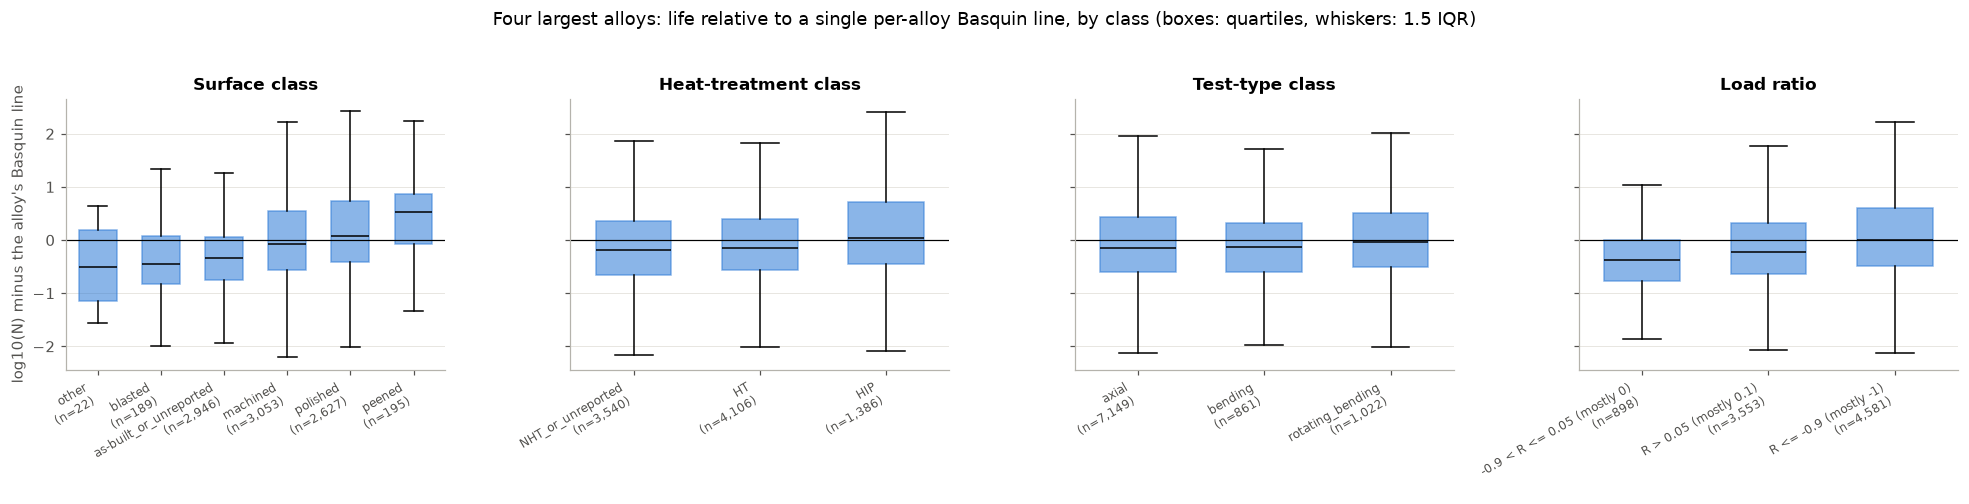

,feature,class,points,articles,median life vs alloy line (log10)
0,surface_class,other,22,3,-0.51
1,surface_class,blasted,189,12,-0.44
2,surface_class,as-built_or_unreported,2946,122,-0.34
3,surface_class,machined,3053,118,-0.07
4,surface_class,polished,2627,119,0.08
5,surface_class,peened,195,16,0.53
6,heat_treatment_class,NHT_or_unreported,3540,164,-0.18
7,heat_treatment_class,HT,4106,163,-0.15
8,heat_treatment_class,HIP,1386,71,0.03
9,test_type_class,axial,7149,238,-0.15


In [16]:
main_alloys = cohort["alloy"].value_counts().index[:4].tolist()
main = cohort[cohort["alloy"].isin(main_alloys)].copy()
main["life_vs_alloy_line"] = np.nan
for alloy in main_alloys:
    mask = main["alloy"] == alloy
    slope, intercept = np.polyfit(main.loc[mask, "log_sa"], main.loc[mask, "log_N"], 1)
    main.loc[mask, "life_vs_alloy_line"] = main.loc[mask, "log_N"] - (intercept + slope * main.loc[mask, "log_sa"])
main["R_class"] = np.select([main["R"] <= -0.9, main["R"].between(-0.9, 0.05, inclusive="right")], ["R <= -0.9 (mostly -1)", "-0.9 < R <= 0.05 (mostly 0)"], default="R > 0.05 (mostly 0.1)")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
panels = [("surface_class", "Surface class"), ("heat_treatment_class", "Heat-treatment class"), ("test_type_class", "Test-type class"), ("R_class", "Load ratio")]
summary_rows = []
for ax, (column, title) in zip(axes, panels):
    order = main.groupby(column)["life_vs_alloy_line"].median().sort_values().index.tolist()
    data = [main.loc[main[column] == level, "life_vs_alloy_line"] for level in order]
    box = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6, medianprops={"color": "black"})
    for patch in box["boxes"]:
        patch.set(facecolor=PALETTE[0], alpha=0.55, edgecolor=PALETTE[0])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([f"{level}\n(n={len(d):,})" for level, d in zip(order, data)], rotation=30, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    for level, d in zip(order, data):
        summary_rows.append({"feature": column, "class": level, "points": len(d), "articles": int(main.loc[main[column] == level, "article_id"].nunique()),
                             "median life vs alloy line (log10)": round(float(d.median()), 2)})
axes[0].set_ylabel("log10(N) minus the alloy's Basquin line")
fig.suptitle("Four largest alloys: life relative to a single per-alloy Basquin line, by class (boxes: quartiles, whiskers: 1.5 IQR)", y=1.03)
fig.tight_layout()
save_figure(fig, FIG_DIR / "02_life_by_category.png")
plt.show()

category_effects = pd.DataFrame(summary_rows)
category_effects.to_csv(AUDIT_DIR / "category_effects_descriptive.csv", index=False)
display(category_effects)

*Note:* the classes follow known fatigue trends (finished surfaces and HIP live longer, tensile mean stress shortens life), but the scatter inside each class is about one decade in life.

## 10. Leakage check on the feature lists

Confirm that no forbidden column (life, run-out flag, identifiers) is in any feature list, and that the tier-0 features have no missing values.

In [17]:
for name, features in [("tier 0 (primary)", fu.FEATURES_TIER0), ("tier 1", fu.FEATURES_TIER1), ("tier 2", fu.FEATURES_TIER2)]:
    fu.assert_features_allowed(features)
    print(f"{name:17s}: {features}")
print("\nForbidden as inputs:", fu.FORBIDDEN)
print("Overlap between tier-0 features and forbidden columns:", sorted(set(fu.FEATURES_TIER0) & set(fu.FORBIDDEN)))

print("\nMissing values in the tier-0 features of the modelling dataset:")
print(cohort[fu.FEATURES_TIER0].isna().sum().to_string())

tier 0 (primary) : ['log_sa', 'R', 'log_swt', 'alloy', 'am_process', 'surface_class', 'heat_treatment_class', 'test_type_class']
tier 1           : ['log_sa', 'R', 'log_swt', 'kt', 'log_frequency', 'alloy', 'am_process', 'surface_class', 'heat_treatment_class', 'test_type_class', 'build_direction_class']
tier 2           : ['log_sa', 'R', 'log_swt', 'sa_over_uts', 'log_uts', 'alloy', 'am_process', 'surface_class', 'heat_treatment_class', 'test_type_class']

Forbidden as inputs: ['N', 'log_N', 'runout', 'is_runout', 'row_id', 'curve_id', 'dataset_id', 'article_id', 'article_group_id', 'author_cluster_id', 'in_near_duplicate_pair', 'doi', 'title', 'authors', 'institution', 'country', 'funding', 'year', 'journal', 'rating_score', 'extraction_method', 'temperature_evidence', 'test_machine']
Overlap between tier-0 features and forbidden columns: []

Missing values in the tier-0 features of the modelling dataset:
log_sa                  0
R                       0
log_swt                 0
a

## 11. Save the processed datasets

Save `modelling_dataset.csv` (failures only, used by all experiments), `sn_cohort_with_runouts.csv` (run-out sensitivity only) and `feature_config.json`.

In [18]:
id_columns = ["row_id", "curve_id", "article_id", "article_group_id", "author_cluster_id"]
feature_columns = fu.FEATURES_TIER0 + ["kt", "log_frequency", "build_direction_class", "sa_over_uts", "log_uts"]
extra_columns = ["stress_amplitude", "N", "sigma_max", "sigma_mean", "uts_mpa", "alloy_family", "in_near_duplicate_pair",
                 "test_temperature_c", "temperature_evidence"]
# The original test-method strings, kept as audit columns for the checks of notebook 04 and supplementary analysis B.
# They are not part of any primary feature tier; the machine name is on the forbidden list (it can identify a laboratory).
for frame in (cohort, with_runouts):
    frame["test_type_raw"] = frame["test_type"].astype(str)
    frame["frequency_text"] = frame["frequency_hz"].astype(str)
audit_columns = ["test_type_raw", "load_control", "frequency_text", "test_machine"]
saved_columns = id_columns + ["log_N"] + feature_columns + extra_columns + audit_columns

modelling = cohort[saved_columns].sort_values("row_id").reset_index(drop=True)
with_runouts_out = with_runouts.assign(is_runout=with_runouts["runout"].astype(int))[saved_columns + ["is_runout"]].sort_values("row_id").reset_index(drop=True)

assert modelling["row_id"].is_unique
assert len(modelling) == int(funnel_table["points"].iloc[-1]), "The funnel's last row must equal the modelling dataset."
assert modelling[fu.FEATURES_TIER0 + ["log_N"]].notna().all().all(), "Tier-0 features and the target must be complete."
assert np.isfinite(modelling[["log_N", "log_sa", "log_swt"]]).all().all()

modelling.to_csv(PROCESSED_DIR / "modelling_dataset.csv", index=False, encoding="utf-8")
with_runouts_out.to_csv(PROCESSED_DIR / "sn_cohort_with_runouts.csv", index=False, encoding="utf-8")

feature_config = {
    "target": fu.TARGET,
    "tier0": {"numeric": fu.NUMERIC_TIER0, "categorical": fu.CATEGORICAL_TIER0},
    "tier1": {"numeric": fu.NUMERIC_TIER1, "categorical": fu.CATEGORICAL_TIER1},
    "tier2": {"numeric": fu.NUMERIC_TIER2, "categorical": fu.CATEGORICAL_TIER2},
    "group_columns": id_columns,
    "forbidden_inputs": fu.FORBIDDEN,
    "rows": int(len(modelling)), "curves": int(modelling["curve_id"].nunique()), "articles": int(modelling["article_id"].nunique()),
}
du.save_json(feature_config, PROCESSED_DIR / "feature_config.json")

print(f"Saved modelling_dataset.csv        : {modelling.shape[0]:,} rows x {modelling.shape[1]} columns")
print(f"Saved sn_cohort_with_runouts.csv   : {with_runouts_out.shape[0]:,} rows x {with_runouts_out.shape[1]} columns")
modelling.head()

Saved modelling_dataset.csv        : 12,666 rows x 32 columns
Saved sn_cohort_with_runouts.csv   : 14,414 rows x 33 columns


,row_id,curve_id,article_id,article_group_id,author_cluster_id,log_N,log_sa,R,log_swt,alloy,am_process,surface_class,heat_treatment_class,test_type_class,kt,log_frequency,build_direction_class,sa_over_uts,log_uts,stress_amplitude,N,sigma_max,sigma_mean,uts_mpa,alloy_family,in_near_duplicate_pair,test_temperature_c,temperature_evidence,test_type_raw,load_control,frequency_text,test_machine
0,0,1,10.1002/adem.202200751,10.1002/adem.202200751,10.1002/adem.202200751,4.302067,2.369151,0.1,2.542545,316L,L-PBF,polished,NHT_or_unreported,axial,1.0,1.0,horizontal_0,0.356654,2.816904,233.965265,20047.798627,519.922812,285.957546,656.0,Steel,False,25,"25, default or reported",uniaxial,force,10,Schenck PSB100
1,1,1,10.1002/adem.202200751,10.1002/adem.202200751,10.1002/adem.202200751,4.704410,2.334264,0.1,2.507658,316L,L-PBF,polished,NHT_or_unreported,axial,1.0,1.0,horizontal_0,0.329125,2.816904,215.905854,50630.187289,479.790788,263.884933,656.0,Steel,False,25,"25, default or reported",uniaxial,force,10,Schenck PSB100
2,2,1,10.1002/adem.202200751,10.1002/adem.202200751,10.1002/adem.202200751,4.974845,2.296664,0.1,2.470058,316L,L-PBF,polished,NHT_or_unreported,axial,1.0,1.0,horizontal_0,0.301828,2.816904,197.999439,94372.343349,439.998753,241.999314,656.0,Steel,False,25,"25, default or reported",uniaxial,force,10,Schenck PSB100
3,3,1,10.1002/adem.202200751,10.1002/adem.202200751,10.1002/adem.202200751,5.183543,2.255313,0.1,2.428706,316L,L-PBF,polished,NHT_or_unreported,axial,1.0,1.0,horizontal_0,0.274416,2.816904,180.016661,152595.813892,400.037025,220.020364,656.0,Steel,False,25,"25, default or reported",uniaxial,force,10,Schenck PSB100
4,4,1,10.1002/adem.202200751,10.1002/adem.202200751,10.1002/adem.202200751,5.432247,2.209099,0.1,2.382493,316L,L-PBF,polished,NHT_or_unreported,axial,1.0,1.0,horizontal_0,0.246715,2.816904,161.845026,270549.972140,359.655614,197.810588,656.0,Steel,False,25,"25, default or reported",uniaxial,force,10,Schenck PSB100


## 12. Gate 3: enough data to model?

Check that the dataset has at least 40 articles, and list the alloys with at least 15 articles.

In [19]:
overall = du.count_points_curves_articles(modelling, curve_col="curve_id")
by_alloy = (modelling.groupby("alloy").agg(points=("row_id", "size"), curves=("curve_id", "nunique"), articles=("article_id", "nunique"))
            .sort_values("points", ascending=False))
gate3 = pd.concat([pd.DataFrame([overall], index=["ALL ALLOYS"]), by_alloy.head(5)])
gate3["median points per curve"] = [modelling.groupby("curve_id").size().median()] + [modelling[modelling["alloy"] == a].groupby("curve_id").size().median() for a in by_alloy.head(5).index]
gate3.to_csv(AUDIT_DIR / "gate3_final_dataset_counts.csv")
display(gate3)

print("Gate 3 (at least 40 articles):", "PASSED" if overall["articles"] >= 40 else "NOT MET")
print("Alloys with at least 15 articles:", ", ".join(f"{a} ({n})" for a, n in by_alloy.loc[by_alloy["articles"] >= 15, "articles"].items()))
print(f"Target: mean log10(N) = {modelling['log_N'].mean():.3f}, standard deviation = {modelling['log_N'].std():.3f}")

,points,curves,articles,median points per curve
ALL ALLOYS,12666,1533,440,7.0
Ti-6Al-4V,4770,546,152,8.0
AlSi10Mg,1465,176,54,8.0
IN718,1434,170,44,8.0
316L,1363,170,49,8.0
17-4 PH,416,46,16,8.5


Gate 3 (at least 40 articles): PASSED
Alloys with at least 15 articles: Ti-6Al-4V (152), AlSi10Mg (54), IN718 (44), 316L (49), 17-4 PH (16)
Target: mean log10(N) = 5.321, standard deviation = 0.993


## 13. Summary

- The join is lossless; the main loss in the funnel is the planned exclusion of run-outs.
- The modelling dataset has 12,666 failure points, 1,533 curves and 440 articles, with eight complete tier-0 features.
- Category labels keep defaults visible (`NHT_or_unreported`, `as-built_or_unreported`).
- 8.4% of the points are on re-published curves, so "unseen article" is weaker than "unseen laboratory".
- Notebook 03 builds the validation folds and trains the models.